# Ising: Metropolis

In [22]:
import numpy as np
import torch
import matplotlib.pyplot as plt
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if device.type == 'cpu':
    torch.set_num_threads(1)
torch.manual_seed(7)
SIZES = (4, 8, 16, 32, 64)
TEMPERATURES = np.array([1.6, 1.9, 2.05, 2.15, 2.22, 2.27, 2.32,
                         2.4, 2.5, 2.7, 3.0, 3.5, 4.0, 4.4])
ENSEMBLES, BURN, SAMPLES, STRIDE = 8, 2000, 800, 2
Tc = 2 / np.log(1 + np.sqrt(2))
print(f'PyTorch {torch.__version__} | {device}')

PyTorch 2.7.1+cu126 | cuda


In [23]:
RULE = 'metropolis'

try:
    from numba import njit
except ImportError:
    njit = None
if njit is not None:
    @njit
    def _seed(seed):
        np.random.seed(seed)
    @njit
    def _cpu_step(s, T, metropolis):
        R, L, _ = s.shape
        for color in range(2):
            for r in range(R):
                for y in range(L):
                    for x in range(L):
                        if (x+y) % 2 != color:
                            continue
                        h = (s[r, (y+1)%L, x] + s[r, (y-1+L)%L, x] +
                             s[r, y, (x+1)%L] + s[r, y, (x-1+L)%L])
                        dE = 2*s[r, y, x]*h
                        p = min(1.0, np.exp(-dE/T)) if metropolis else 1/(1+np.exp(dE/T))
                        if np.random.random() < p:
                            s[r, y, x] = -s[r, y, x]
    _seed(7)

checker_cache = {}
def step(s, T):
    L = s.shape[-1]
    if device.type == 'cpu' and njit is not None:
        _cpu_step(s.numpy(), T, RULE == 'metropolis')
        return s
    if L not in checker_cache:
        i = torch.arange(L, device=device)
        checker_cache[L] = (i[:, None]+i[None, :]) % 2
    checker = checker_cache[L]
    for color in (0, 1):
        h = (torch.roll(s, 1, -1)+torch.roll(s, -1, -1)+
             torch.roll(s, 1, -2)+torch.roll(s, -1, -2))
        dE = (2*s*h).float()
        p = torch.exp(-dE.clamp_min(0)/T) if RULE == 'metropolis' else torch.sigmoid(-dE/T)
        flip = (checker == color)[None] & (torch.rand(s.shape, device=device) < p)
        s[flip] *= -1
    return s

In [24]:
def observables(moments, L, T):
    mabs, m2, m4 = moments
    return np.array([L*L*(m2-mabs*mabs)/T, 1-m4/(3*m2*m2)])

def scan(sizes=SIZES, temperatures=TEMPERATURES, ensembles=ENSEMBLES,
         burn=BURN, samples=SAMPLES, stride=STRIDE):
    assert ensembles > 1 and all(L % 2 == 0 for L in sizes)
    values = np.empty((len(sizes), len(temperatures), 2))
    errors = np.empty_like(values)
    for i, L in enumerate(sizes):
        for j, T in enumerate(temperatures):
            s = (2*torch.randint(0, 2, (ensembles, L, L), device=device)-1).to(torch.int8)
            for _ in range(burn):
                step(s, float(T))
            moments = torch.zeros((ensembles, 3), device=device)
            for _ in range(samples):
                for _ in range(stride):
                    step(s, float(T))
                m = s.float().mean((-2, -1))
                m2 = m.square()
                moments += torch.stack((m.abs(), m2, m2.square()), 1)
            moments = (moments/samples).cpu().numpy()
            values[i, j] = observables(moments.mean(0), L, T)
            leave_one_out = (moments.sum(0)-moments)/(ensembles-1)
            jk = np.array([observables(x, L, T) for x in leave_one_out])
            errors[i, j] = np.sqrt((ensembles-1)/ensembles *
                                    ((jk-jk.mean(0))**2).sum(0))
    return values, errors

values, errors = scan()

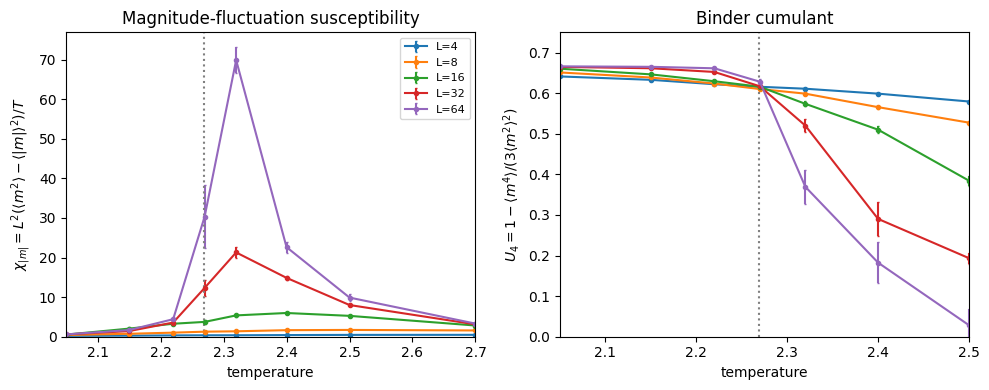

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
labels = [r'$\chi_{|m|}=L^2(\langle m^2\rangle-\langle|m|\rangle^2)/T$',
          r'$U_4=1-\langle m^4\rangle/(3\langle m^2\rangle^2)$']
for i, L in enumerate(SIZES):
    for k in range(2):
        ax[k].errorbar(TEMPERATURES, values[i, :, k], yerr=errors[i, :, k],
                       marker='o', ms=3, capsize=1, label=f'L={L}')
for a, label in zip(ax, labels):
    a.axvline(Tc, color='gray', ls=':')
    a.set(xlabel='temperature', ylabel=label)
ax[0].set(title='Magnitude-fluctuation susceptibility', xlim=(2.05, 2.7), ylim=(0, None))
ax[1].set(title='Binder cumulant', xlim=(2.05, 2.5), ylim=(0, .75))
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## Dynamics video

In [26]:
from pathlib import Path
from IPython.display import Video, display

video_path = Path('Ising_dynamics_three_temperatures.mp4')
if not video_path.exists():
    import shutil
    import sysconfig
    from matplotlib.animation import FFMpegWriter
    ffmpeg = shutil.which('ffmpeg')
    if ffmpeg is None:
        candidate = Path(sysconfig.get_path('scripts')) / 'ffmpeg.exe'
        ffmpeg = str(candidate) if candidate.is_file() else None
    if ffmpeg is None:
        raise FileNotFoundError(f'{video_path} is missing; install ffmpeg to regenerate it')
    plt.rcParams['animation.ffmpeg_path'] = ffmpeg
    temperatures = (1.8, Tc, 3.0)
    spins = (2*torch.randint(0, 2, (1, 64, 64), device=device)-1).to(torch.int8)
    lattices = [spins.clone() for _ in temperatures]
    fig, ax = plt.subplots(1, 3, figsize=(9, 3))
    images = [a.imshow(s[0].cpu(), cmap='coolwarm', vmin=-1, vmax=1)
              for a, s in zip(ax, lattices)]
    for a, title in zip(ax, [r'$T=1.8<T_c$', r'$T=T_c$', r'$T=3.0>T_c$']):
        a.set(title=title, xticks=[], yticks=[])
    writer = FFMpegWriter(fps=12, codec='libx264', extra_args=['-pix_fmt', 'yuv420p'])
    with writer.saving(fig, str(video_path), dpi=120):
        for _ in range(96):
            for _ in range(4):
                for s, T in zip(lattices, temperatures):
                    step(s, T)
            for image, s in zip(images, lattices):
                image.set_data(s[0].cpu().numpy())
            writer.grab_frame()
    plt.close(fig)
display(Video(str(video_path), embed=True))